## A. Preliminary Study of periodic signals within Firefly images

0. Load the 1000 Firefly images in luminance.
1. Group them by size
2. Compute the mean image for growing sample sizes.
3. Work on the residuals.
4. Compute the autocorrelation and read off the periods.
5. Summarize the strongest peaks in a table.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import convolve, gaussian_filter, maximum_filter

# Project folders. The notebook may be started from the project root or from notebooks/,
# so we walk up until we find the folder containing pyproject.toml.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RESULTS_DIR = PROJECT_ROOT / "results"
FIREFLY_DIR = PROJECT_ROOT / "data" / "synthbuster" / "synthbuster" / "firefly"
OUT = RESULTS_DIR / "01_mean_autocorr"  # cache of the mean images
OUT.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(0)

# Growing sample sizes. The full set of images of each size is always added as the
# last N; values larger than that set are skipped.
SAMPLE_SIZES = [10, 20, 50, 100]

In [2]:
LUMA_WEIGHTS = np.array([0.299, 0.587, 0.114])


def load_luminance(path):
    """Read an image and return its luminance as a float64 array (values in [0, 255])."""
    with Image.open(path) as img:
        rgb = np.asarray(img.convert("RGB"), dtype=np.float64)
    return rgb @ LUMA_WEIGHTS


def group_by_size(paths):
    """{(width, height): [paths]}, largest group first. Only reads the file headers."""
    groups = {}
    for p in paths:
        with Image.open(p) as img:
            groups.setdefault(img.size, []).append(p)
    return dict(sorted(groups.items(), key=lambda kv: -len(kv[1])))


paths = sorted(FIREFLY_DIR.glob("*.png"))
print(f"{len(paths)} images in {FIREFLY_DIR}")

1000 images in c:\Users\henry\Desktop\Firefly-detection\data\synthbuster\synthbuster\firefly


# 1. Loading the different groups of images

In [3]:
groups = group_by_size(paths)
# Random, seeded order so that "the first N images" is a random sample;
# samples are nested: the first N images are part of every larger sample.
groups = {size: [paths[i] for i in rng.permutation(len(paths))] for size, paths in groups.items()}
pd.DataFrame(
    [(f"{w}x{h}", len(p)) for (w, h), p in groups.items()],
    columns=["taille (largeur x hauteur, px)", "nombre d'images"],
).style.hide(axis="index").set_caption("Images Firefly regroupées par taille")

"taille (largeur x hauteur, px)",nombre d'images
2304x1792,271
1792x2304,252
2048x2048,243
2688x1536,234


In [4]:
def running_means(paths, checkpoints):
    """Mean over the first n paths for each n in checkpoints, in a single pass."""
    checkpoints = sorted(set(checkpoints))
    means, acc = {}, None
    for k, path in enumerate(paths[: checkpoints[-1]], 1):
        img = load_luminance(path)
        acc = img if acc is None else acc + img
        if k in checkpoints:
            means[k] = acc / k
    return means


def cached_means(size, paths, ns):
    files = {n: OUT / f"mean_{size[0]}x{size[1]}_n{n}.npy" for n in ns}
    if all(f.exists() for f in files.values()):
        return {n: np.load(f) for n, f in files.items()}
    means = running_means(paths, ns)
    for n, m in means.items():
        np.save(files[n], m)
    return means

# 2. Computing the mean images

$$I_k = I_k^0 + S + \Theta_k, \qquad \bar I_N = \frac1N \sum_{k=1}^N I_k \;=\; S + \frac1N\sum_{k=1}^N \big(I^0_k + \Theta_k\big)$$

In [5]:
means = {}  # (size, N) -> mean luminance image
sample_ns = {}  # size -> list of N
for size, paths in groups.items():
    sample_ns[size] = sorted({n for n in SAMPLE_SIZES if n < len(paths)} | {len(paths)})
    for n, m in cached_means(size, paths, sample_ns[size]).items():
        means[size, n] = m
    print(f"{size[0]}x{size[1]}: N = {sample_ns[size]}")

sizes = list(groups)
n_cols = max(len(ns) for ns in sample_ns.values())

def plot_means(size):
    """Moyennes pour une taille d'image : une figure, une colonne par N."""
    ns = sample_ns[size]
    fig, axes = plt.subplots(1, len(ns), figsize=(4.0 * len(ns), 4), squeeze=False)
    for ax, n in zip(axes[0], ns):
        ax.imshow(means[size, n], cmap="gray")
        ax.set_title(f"N={n}")
        ax.axis("off")
    fig.suptitle(f"Mean image, {size[0]}x{size[1]}")
    fig.tight_layout()
    plt.show()

2304x1792: N = [10, 20, 50, 100, 271]
1792x2304: N = [10, 20, 50, 100, 252]
2048x2048: N = [10, 20, 50, 100, 243]
2688x1536: N = [10, 20, 50, 100, 234]


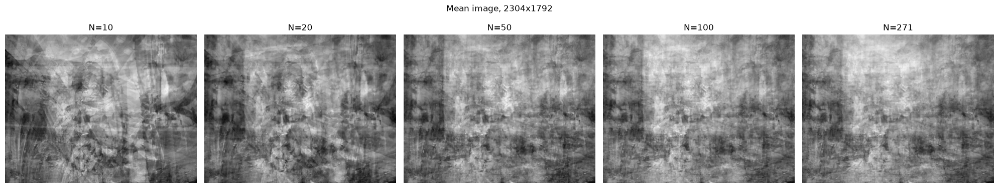

In [6]:
plot_means(sizes[0])   # 2304x1792

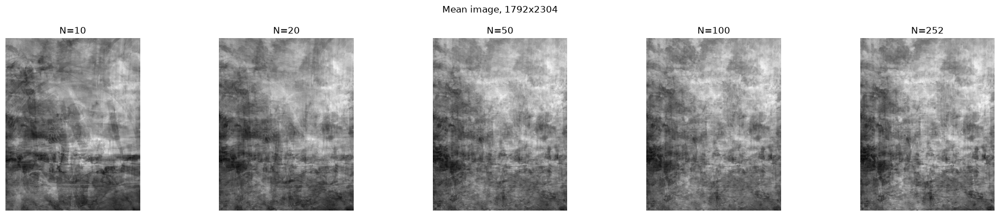

In [7]:
plot_means(sizes[1])   # 1792x2304

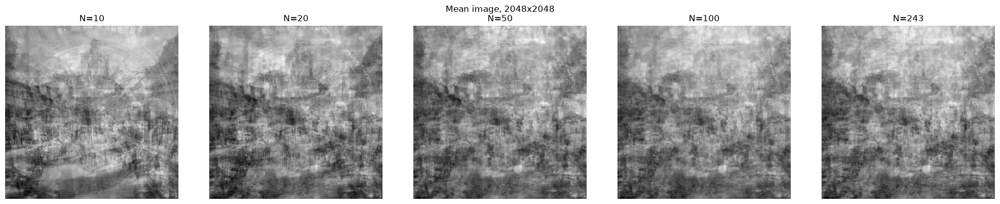

In [8]:
plot_means(sizes[2])   # 2048x2048

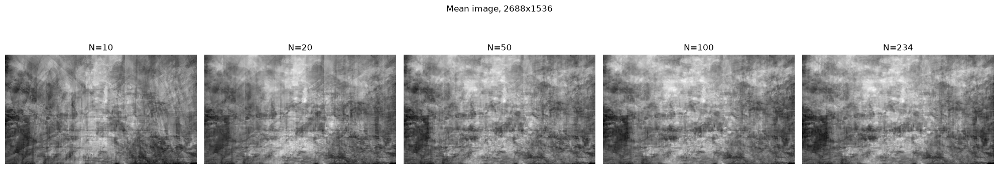

In [9]:
plot_means(sizes[3])   # 2688x1536

# 3. Filtering : 

We can choose to apply some different filtering to study the residuals : 

- `"gaussian"`: residual of a Gaussian blur, $X = \bar I_N - G_\sigma * \bar I_N$ with $\sigma = 2$ : 

$$
G_\sigma(y, x) = \frac{1}{2\pi\sigma^2}\, \exp\!\left(-\frac{x^2 + y^2}{2\sigma^2}\right)
$$
- `"laplace"`: residual given by the kernel
  $$
  K = \begin{pmatrix} 0 & -\tfrac12 & 0 \\ -\tfrac12 & 2 & -\tfrac12 \\ 0 & -\tfrac12 & 0 \end{pmatrix},
  \qquad X = K * \bar I_N = 2\Big(\bar I_N - \tfrac14\big(\text{sum of the 4 neighbours}\big)\Big).
  $$

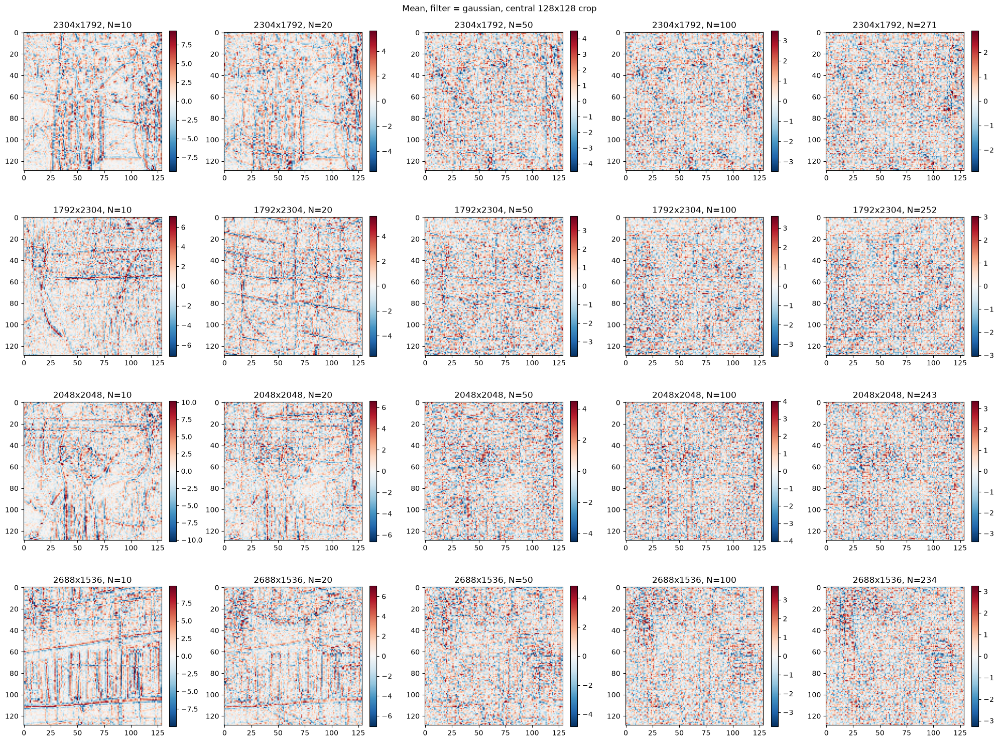

In [10]:
FILTER = "gaussian"  # "none", "gaussian" or "laplace"

SIGMA = 1
K_LAPLACE = np.array([[0, -0.5, 0],
                      [-0.5, 2, -0.5],
                      [0, -0.5, 0]])


def gaussian_residual(x, sigma=SIGMA):
    return x - gaussian_filter(x, sigma, mode="wrap", radius=3)


def laplace_residual(x):
    return convolve(x, K_LAPLACE, mode="wrap")


FILTERS = {"none": lambda x: x, "gaussian": gaussian_residual, "laplace": laplace_residual}


def crop_center(x, half):
    cy, cx = x.shape[0] // 2, x.shape[1] // 2
    return x[cy - half : cy + half + 1, cx - half : cx + half + 1]


hp = {key: FILTERS[FILTER](m) for key, m in means.items()}


# Figure : Zoom sur le centre : carré de 128*128 pixels

fig, axes = plt.subplots(
    len(sizes), n_cols, figsize=(4.0 * n_cols, 3.8 * len(sizes)), squeeze=False
)
for row, size in zip(axes, sizes):
    for ax in row[len(sample_ns[size]) :]:
        ax.axis("off")
    for ax, n in zip(row, sample_ns[size]):
        c = crop_center(hp[size, n], 64)
        c = c
        #c = c - c.mean()
        v = np.percentile(np.abs(c), 99.5)
        im = ax.imshow(c, cmap="RdBu_r", vmin=-v, vmax=v)
        ax.set_title(f"{size[0]}x{size[1]}, N={n}")
        fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"Mean, filter = {FILTER}, central 128x128 crop")
fig.tight_layout()

Les contours des images visibles à $N = 10$
disparaissent avec $N$ ; l'amplitude baisse (≈ ±12 → ±5 niveaux de gris).

# 4. autocorrélation 
On calcule l'autocorrélatoin à partir du théorème de Wiener-Khinchin :

$$
R_X(\Delta y, \Delta x) = \frac{\sum_{y,x} \big(X(y,x) - \mu_X\big)\big(X(y+\Delta y, x+\Delta x) - \mu_X\big)}{\sum_{y,x} \big(X(y,x) - \mu_X\big)^2}
\;=\; \frac{\mathcal F^{-1}\{|\mathcal F\{X - \mu_X\}|^2\}}{\sum (X - \mu_X)^2}
$$

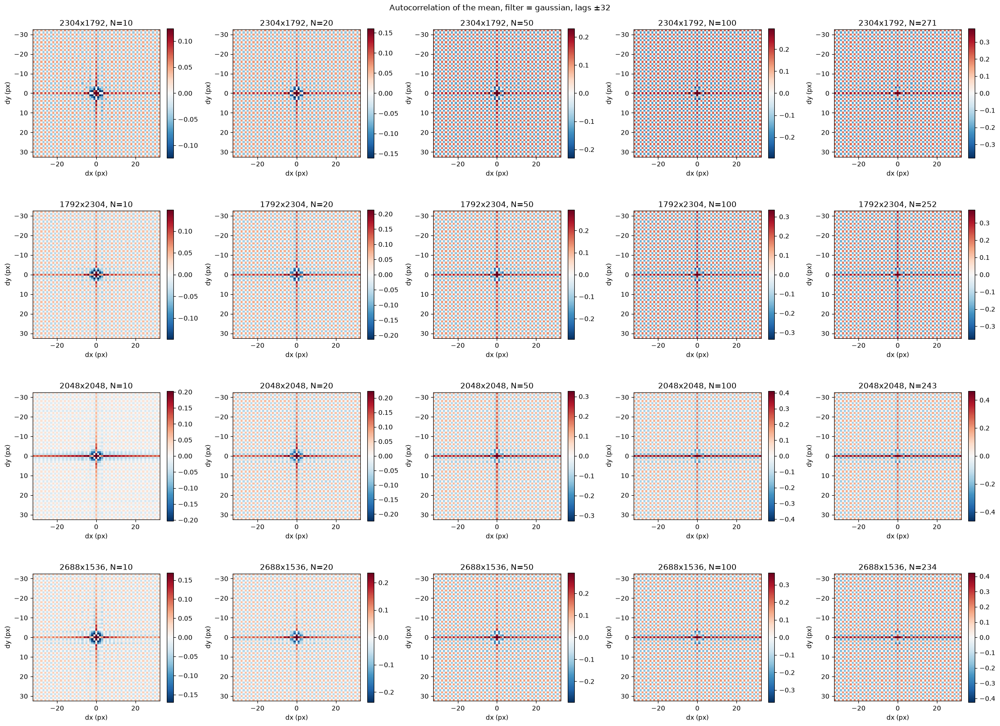

In [11]:
LAG = 32
lags = np.arange(-LAG, LAG + 1)

def autocorrelation(x):
    x = x - x.mean()
    r = np.fft.ifft2(np.abs(np.fft.fft2(x)) ** 2).real
    return np.fft.fftshift(r / r.flat[0])


acf = {key: crop_center(autocorrelation(h), LAG) for key, h in hp.items()}

fig, axes = plt.subplots(
    len(sizes), n_cols, figsize=(4.3 * n_cols, 4 * len(sizes)), squeeze=False
)
ext = (-LAG - 0.5, LAG + 0.5, LAG + 0.5, -LAG - 0.5)
for row, size in zip(axes, sizes):
    for ax in row[len(sample_ns[size]) :]:
        ax.axis("off")
    for ax, n in zip(row, sample_ns[size]):
        r = acf[size, n].copy()
        r[LAG - 2 : LAG + 3, LAG - 2 : LAG + 3] = 0  # hide the zero-lag peak
        v = np.abs(r).max()
        im = ax.imshow(acf[size, n], cmap="RdBu_r", vmin=-v, vmax=v, extent=ext)
        ax.set_title(f"{size[0]}x{size[1]}, N={n}")
        ax.set_xlabel("dx (px)")
        ax.set_ylabel("dy (px)")
        fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"Autocorrelation of the mean, filter = {FILTER}, lags ±{LAG}")
fig.tight_layout()

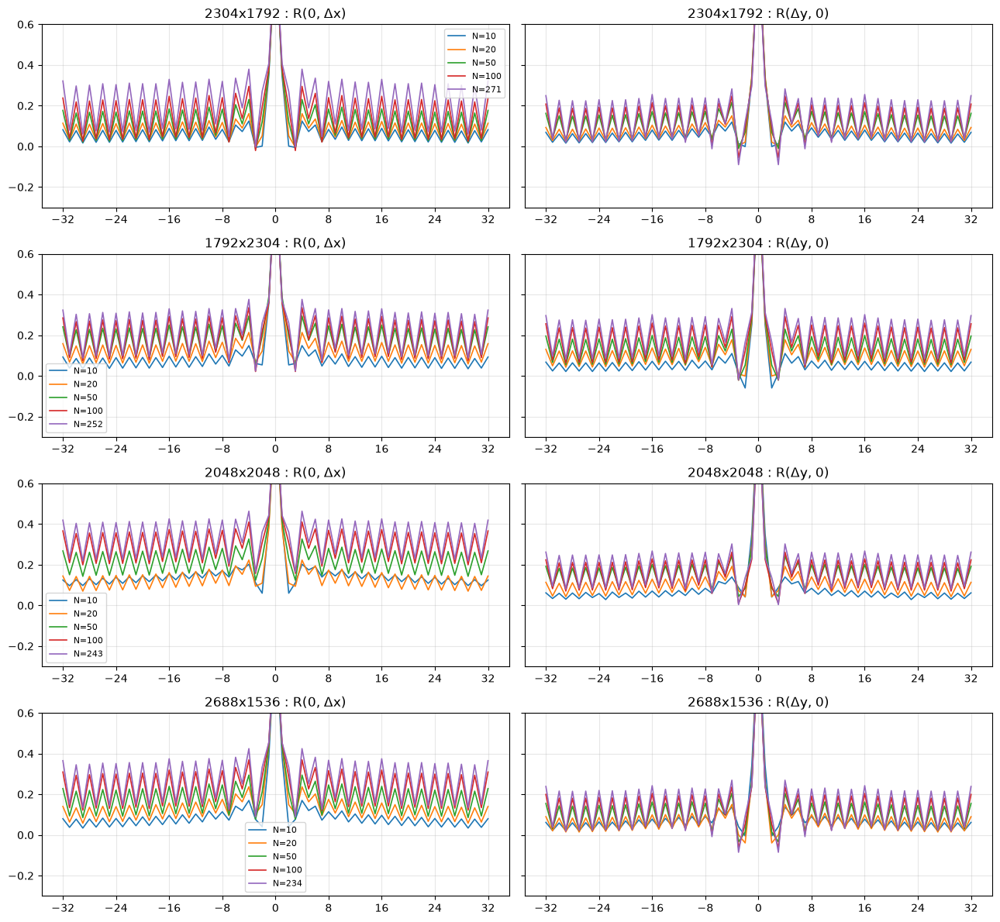

In [12]:
#auto-corrélation selon un axe donné : 

fig, axes = plt.subplots(len(sizes), 2, figsize=(13, 3 * len(sizes)), sharey=True, squeeze=False)
for row, size in zip(axes, sizes):
    for n in sample_ns[size]:
        row[0].plot(lags, acf[size, n][LAG, :], lw=1.2, label=f"N={n}")
        row[1].plot(lags, acf[size, n][:, LAG], lw=1.2, label=f"N={n}")
    row[0].set_title(f"{size[0]}x{size[1]} : R(0, Δx)")
    row[1].set_title(f"{size[0]}x{size[1]} : R(Δy, 0)")
    for ax in row:
        ax.set_ylim(-0.3, 1.05 if FILTER == "none" else 0.6)
        ax.set_xticks(np.arange(-LAG, LAG + 1, 8))
        ax.grid(alpha=0.3)
    row[0].legend(fontsize=8)
fig.tight_layout()

# Comparaison avec un bruit blanc

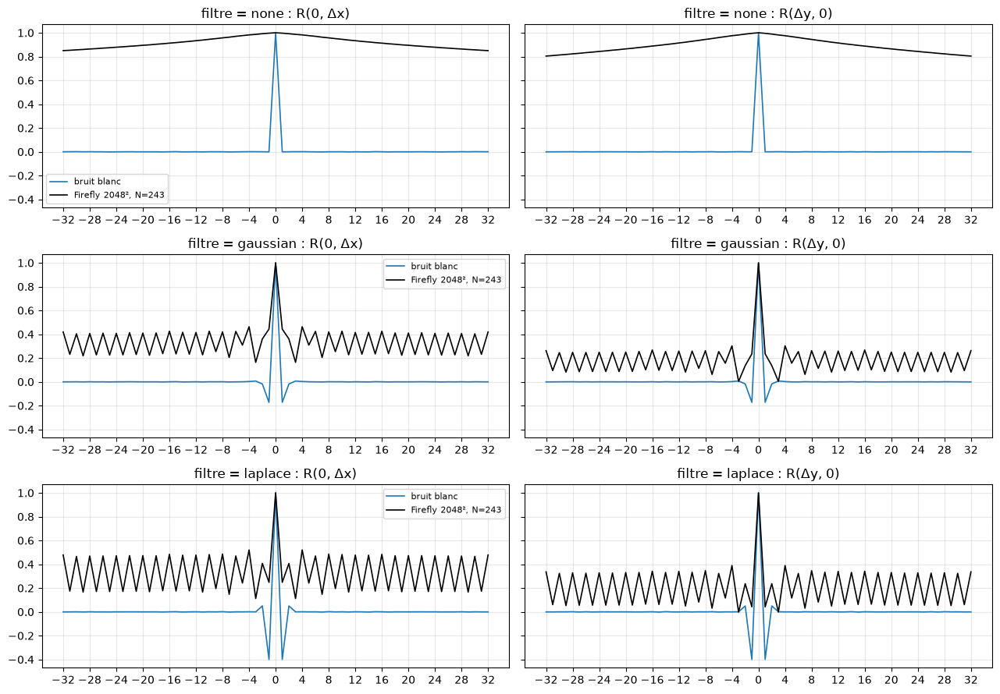

In [13]:
size_ff = (2048, 2048)
mean_ff = means[size_ff, sample_ns[size_ff][-1]]
noise_ctrl = np.random.default_rng(1).standard_normal(mean_ff.shape)
images_ctrl = {"bruit blanc": noise_ctrl, f"Firefly 2048², N={sample_ns[size_ff][-1]}": mean_ff}

fig, axes = plt.subplots(len(FILTERS), 2, figsize=(13, 3 * len(FILTERS)), sharey=True, squeeze=False)
for row, (name, filt) in zip(axes, FILTERS.items()):
    for (label, x), color in zip(images_ctrl.items(), ("tab:blue", "black")):
        r = crop_center(autocorrelation(filt(x)), LAG)
        row[0].plot(lags, r[LAG, :], lw=1.2, color=color, label=label)
        row[1].plot(lags, r[:, LAG], lw=1.2, color=color, label=label)
    row[0].set_title(f"filtre = {name} : R(0, Δx)")
    row[1].set_title(f"filtre = {name} : R(Δy, 0)")
    for ax in row:
        ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
        ax.grid(alpha=0.3)
    row[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [14]:
rows = []
for name, filt in FILTERS.items():
    for label, x in images_ctrl.items():
        y = filt(x) - filt(x).mean()
        rows.append((name, label, *[round(y[p::2, q::2].mean(), 3) for p in (0, 1) for q in (0, 1)], round(y.std(), 3)))
pd.DataFrame(rows, columns=["filtre appliqué", "image",
                            "moyenne des pixels : ligne paire, colonne paire",
                            "moyenne des pixels : ligne paire, colonne impaire",
                            "moyenne des pixels : ligne impaire, colonne paire",
                            "moyenne des pixels : ligne impaire, colonne impaire",
                            "écart-type de l'image filtrée (échelle)"]).style.hide(axis="index").format(precision=3).set_caption(
    "Motif 2x2 moyen de l'image filtrée (moyenne globale retirée) : "
    "moyenne des pixels selon la parité de leur ligne et de leur colonne"
)

filtre appliqué,image,"moyenne des pixels : ligne paire, colonne paire","moyenne des pixels : ligne paire, colonne impaire","moyenne des pixels : ligne impaire, colonne paire","moyenne des pixels : ligne impaire, colonne impaire",écart-type de l'image filtrée (échelle)
none,bruit blanc,0.000,0.000,0.000,-0.001,1.000
none,"Firefly 2048², N=243",-0.061,-0.593,0.773,-0.119,23.903
gaussian,bruit blanc,0.000,0.000,0.000,-0.001,0.873
gaussian,"Firefly 2048², N=243",-0.061,-0.584,0.763,-0.119,1.246
laplace,bruit blanc,-0.000,0.001,0.001,-0.001,2.236
laplace,"Firefly 2048², N=243",-0.301,-1.007,1.726,-0.418,2.146


**Pics les plus forts**

In [15]:
def peaks(r, k=8, exclude=2):
    c = r.shape[0] // 2
    ys, xs = np.nonzero((r == maximum_filter(r, size=3, mode="wrap")) & (r > 0))
    out = [(y - c, x - c, r[y, x]) for y, x in zip(ys, xs)
           if max(abs(y - c), abs(x - c)) > exclude and (y - c, x - c) > (0, 0)]
    return sorted(out, key=lambda p: -p[2])[:k]


rows = []
for (size, n), r in acf.items():
    for rank, (dy, dx, v) in enumerate(peaks(r), 1):
        rows.append((f"{size[0]}x{size[1]}", n, rank, dy, dx, round(v, 3)))
df_peaks = pd.DataFrame(rows, columns=["size", "N", "rank", "dy", "dx", "R"])
(df_peaks.pivot_table(index=["size", "N"], columns="rank", values="R")
 .rename(columns=lambda k: f"pic n°{k}")
 .rename_axis(index=["taille", "N (images moyennées)"], columns=None)
 .style.format(precision=3)
 .set_caption(f"Hauteur R des 8 plus grands pics de l'autocorrélation, du plus haut (n°1) au plus bas "
              f"(décalages à plus de 2 px de l'origine, un seul pic par paire ±), filtre = {FILTER}"))

In [16]:
# Lags of the top peaks with all images
(df_peaks[df_peaks.N == df_peaks.groupby("size").N.transform("max")]
 .pivot_table(index="size", columns="rank", values=["dy", "dx"], aggfunc="first")[["dy", "dx"]]
 .rename(columns={"dy": "Δy : décalage vertical (px)", "dx": "Δx : décalage horizontal (px)"}, level=0)
 .rename(columns=lambda k: f"pic n°{k}", level=1)
 .rename_axis(index="taille", columns=[None, None])
 .style.set_caption("Position (Δy, Δx) des mêmes pics, avec toutes les images de chaque taille"))

## B. Effet des différentes méthodes d'upsampling

**Expérience :** on refait la partie A sur des images simulées, où l'on sait tout :
1. on tire $N = 50$ images de bruit blanc 512×512 (moyenne $\mu = 1$, écart-type 1) : aucune structure au départ ;
2. on les upsample ×2 (→ 1024×1024) avec une méthode donnée ;
3. comme en A : moyenne, filtre (`FILTER`), autocorrélation.

On compare au profil de
Firefly (2048×2048, toutes les images, courbe noire).

In [17]:
N_IMG, N_LOW, MU = 50, 512, 1.0
size_ff = (2048, 2048)
acf_ff = acf[size_ff, sample_ns[size_ff][-1]]


def simulate(upsample):
    # Partie A sur N_IMG images de bruit upsamplées : moyenne, filtre, autocorrélation.
    mean = sum(upsample(MU + rng.standard_normal((N_LOW, N_LOW))) for _ in range(N_IMG)) / N_IMG
    return crop_center(autocorrelation(FILTERS[FILTER](mean)), LAG)


def plot_profiles(acfs, title):
    # Profils R(0, Δx) et R(Δy, 0) des simulations, avec Firefly en noir.
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
    for name, r in acfs.items():
        axes[0].plot(lags, r[LAG, :], lw=1.2, label=name)
        axes[1].plot(lags, r[:, LAG], lw=1.2, label=name)
    axes[0].plot(lags, acf_ff[LAG, :], lw=2, color="black", label="Firefly 2048²")
    axes[1].plot(lags, acf_ff[:, LAG], lw=2, color="black", label="Firefly 2048²")
    axes[0].set(title=f"{title} : R(0, Δx)", xlabel="Δx (px)")
    axes[1].set(title=f"{title} : R(Δy, 0)", xlabel="Δy (px)")
    for ax in axes:
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

## 1. Interpolation classique

Chaque pixel de sortie est une moyenne pondérée des pixels d'entrée voisins ; les poids
(le noyau : nearest, bilinear, bicubic, Lanczos) sont fixes et normalisés à somme 1.

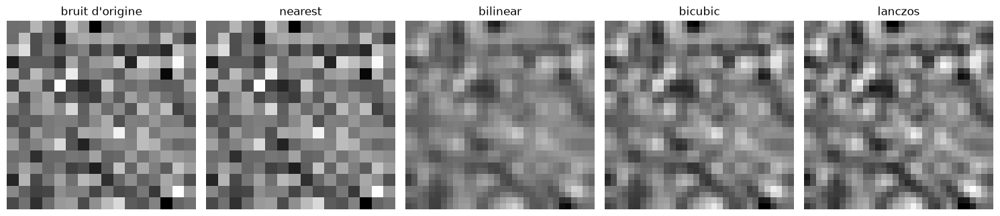

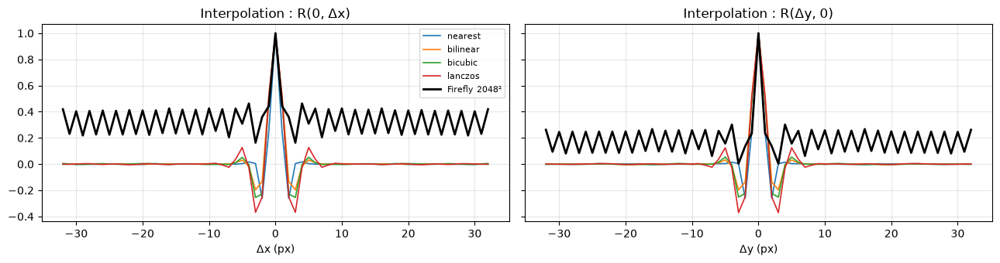

In [18]:
INTERPOLATIONS = {"nearest": Image.NEAREST, "bilinear": Image.BILINEAR,
                  "bicubic": Image.BICUBIC, "lanczos": Image.LANCZOS}


def interpolate(x, method):
    img = Image.fromarray(x.astype(np.float32))
    return np.asarray(img.resize((2 * x.shape[1], 2 * x.shape[0]), INTERPOLATIONS[method]), dtype=np.float64)


# Aperçu : coin 16×16 d'un bruit, upsamplé ×2 par chaque méthode
noise = rng.standard_normal((16, 16))
fig, axes = plt.subplots(1, len(INTERPOLATIONS) + 1, figsize=(3 * (len(INTERPOLATIONS) + 1), 3.2))
axes[0].imshow(noise, cmap="gray", vmin=-2.5, vmax=2.5)
axes[0].set_title("bruit d'origine")
for ax, m in zip(axes[1:], INTERPOLATIONS):
    ax.imshow(interpolate(noise, m), cmap="gray", vmin=-2.5, vmax=2.5)
    ax.set_title(m)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

plot_profiles({m: simulate(lambda x, m=m: interpolate(x, m)) for m in INTERPOLATIONS}, "Interpolation")

## 2. Convolution transposée (noyau d'upsampling appris par le décodeur du modèle ?)

Noyaux testés : bilinéaire 4×4, uniforme 3×3 et aléatoire 3×3
(substitut d'un noyau appris), normalisés à $\sum K = 4$.

$$u[2m,\, 2l] = x[m,\, l], \quad u = 0 \text{ ailleurs}, \qquad y = u * K$$

| noyau | $K$ |
|---|---|
| bilinear 4×4 | $K = h\,h^\top$, $\;h = \frac14(1, 3, 3, 1)$, soit $\frac1{16}\begin{pmatrix} 1 & 3 & 3 & 1 \ 3 & 9 & 9 & 3 \ 3 & 9 & 9 & 3 \ 1 & 3 & 3 & 1 \end{pmatrix}$ |
| box 3×3 | $\frac49\begin{pmatrix} 1 & 1 & 1 \ 1 & 1 & 1 \ 1 & 1 & 1 \end{pmatrix}$ |
| random 3×3 | $K = 4\,K' / \sum K'$, $\;K'_{ij} \sim \mathcal N(1,\, 0{,}5^2)$ (graine 42), soit $\begin{pmatrix} 0{,}59 & 0{,}25 & 0{,}71 \ 0{,}76 & 0{,}01 & 0{,}18 \ 0{,}55 & 0{,}43 & 0{,}51 \end{pmatrix}$ |

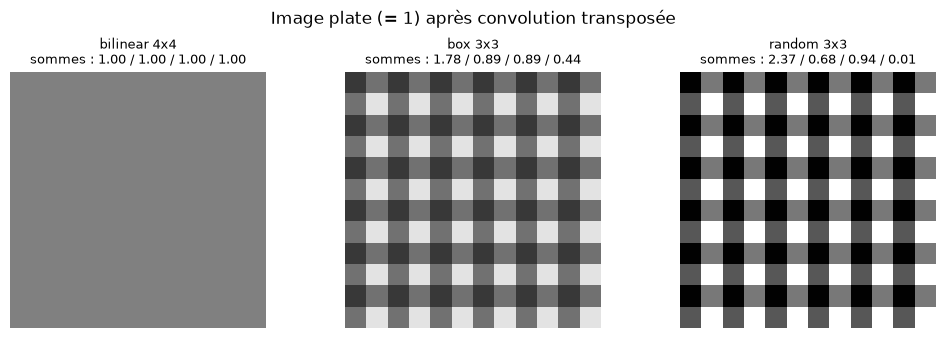

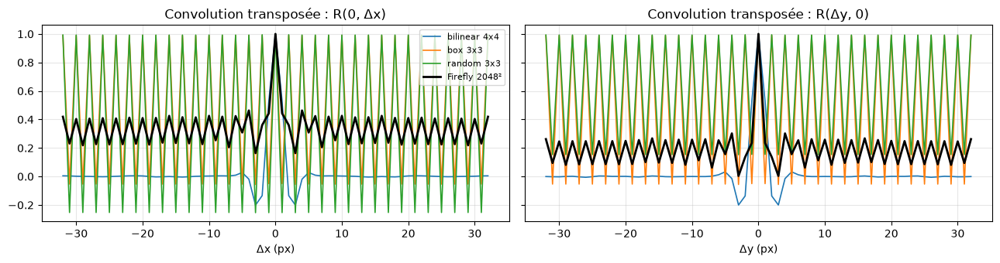

In [19]:
def transposed_conv(x, kernel):
    u = np.zeros((2 * x.shape[0], 2 * x.shape[1]))
    u[::2, ::2] = x  # insertion de zéros
    return convolve(u, kernel, mode="wrap")


h = np.array([1, 3, 3, 1]) / 4
k_random = np.random.default_rng(42).normal(1, 0.5, (3, 3))
TCONV_KERNELS = {"bilinear 4x4": np.outer(h, h),
                 "box 3x3": np.ones((3, 3)) * 4 / 9,
                 "random 3x3": k_random * 4 / k_random.sum()}

# Aperçu : une image plate après convolution transposée
fig, axes = plt.subplots(1, len(TCONV_KERNELS), figsize=(3.4 * len(TCONV_KERNELS), 3.4))
for ax, (name, K) in zip(axes, TCONV_KERNELS.items()):
    ax.imshow(transposed_conv(np.ones((6, 6)), K), cmap="gray", vmin=0, vmax=2)
    sums = [K[p::2, q::2].sum() for p in (0, 1) for q in (0, 1)]
    ax.set_title(f"{name}\nsommes : " + " / ".join(f"{s:.2f}" for s in sums), fontsize=9)
    ax.axis("off")
fig.suptitle("Image plate (= 1) après convolution transposée")
fig.tight_layout()
plt.show()

plot_profiles({name: simulate(lambda x, K=K: transposed_conv(x, K)) for name, K in TCONV_KERNELS.items()},
              "Convolution transposée")

## C. Comparaison avec des images réelles (COCO)

On refait la partie A sur des photos réelles du dataset **COCO** (split `test2017`, ~40 000 images).
On ne télécharge pas l'archive complète (6 Go) :
1. on récupère seulement le fichier d'index `image_info_test2017.json` (~1 Mo zippé), qui donne
   nom de fichier, largeur et hauteur de chaque image ;
2. on garde les images de la taille la plus fréquente (pour pouvoir les moyenner) ;
3. on en tire `N_COCO` au hasard et on les télécharge une par une (~150 Ko chacune) dans `data/coco/`
   (déjà téléchargées → réutilisées).

⚠️ Les images COCO sont des **JPEG** : la compression par blocs 8×8 peut laisser un pic à
$\Delta = 8$ dans l'autocorrélation. Ce n'est pas un artefact d'upsampling.

In [20]:
import io
import json
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor

COCO_URL = "http://images.cocodataset.org"
COCO_DIR = PROJECT_ROOT / "data" / "coco" / "test2017"
COCO_DIR.mkdir(parents=True, exist_ok=True)
N_COCO = 200  # nombre d'images à télécharger (~30 Mo pour 200)


def coco_index():
    # Liste (fichier, largeur, hauteur) des images test2017, mise en cache localement.
    index = COCO_DIR.parent / "image_info_test2017.json"
    if not index.exists():
        with urllib.request.urlopen(f"{COCO_URL}/annotations/image_info_test2017.zip") as r:
            zf = zipfile.ZipFile(io.BytesIO(r.read()))
        index.write_bytes(zf.read("annotations/image_info_test2017.json"))
    images = json.loads(index.read_text())["images"]
    return pd.DataFrame(images)[["file_name", "width", "height"]]


def coco_download(file_names):
    # Télécharge les images manquantes (en parallèle) et renvoie leurs chemins locaux.
    def fetch(name):
        dest = COCO_DIR / name
        if not dest.exists():
            tmp = dest.with_suffix(".part")
            urllib.request.urlretrieve(f"{COCO_URL}/test2017/{name}", tmp)
            tmp.rename(dest)
        return dest

    with ThreadPoolExecutor(max_workers=16) as pool:
        return list(pool.map(fetch, file_names))


coco = coco_index()
size_coco = coco.groupby(["width", "height"]).size().idxmax()
candidates = coco[(coco.width == size_coco[0]) & (coco.height == size_coco[1])].file_name.sort_values()
print(f"{len(coco)} images COCO, dont {len(candidates)} en {size_coco[0]}x{size_coco[1]}")

picked = candidates.sample(N_COCO, random_state=0).tolist()
coco_paths = coco_download(picked)
print(f"{len(coco_paths)} images prêtes dans {COCO_DIR}")

40670 images COCO, dont 9069 en 640x480
200 images prêtes dans c:\Users\henry\Desktop\Firefly-detection\data\coco\test2017


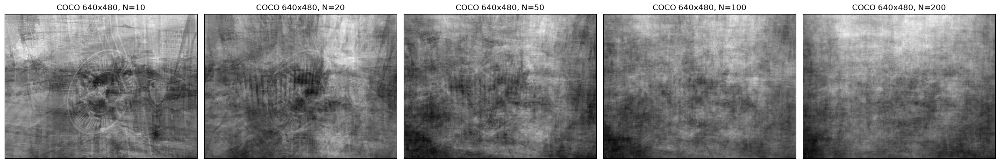

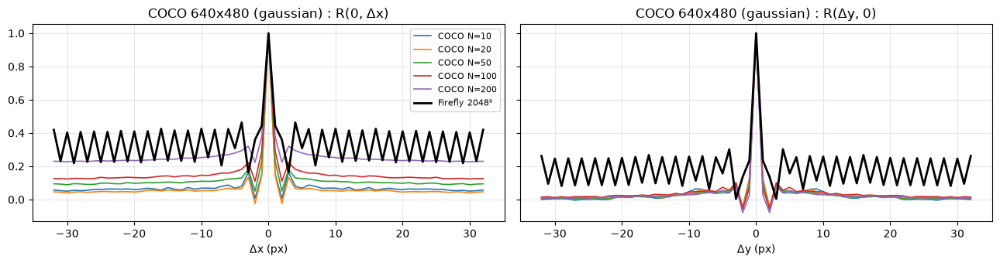

In [21]:
# Même pipeline que la partie A : moyennes, filtre, autocorrélation.
ns_coco = sorted({n for n in SAMPLE_SIZES if n < N_COCO} | {N_COCO})
means_coco = running_means(coco_paths, ns_coco)
acf_coco = {f"COCO N={n}": crop_center(autocorrelation(FILTERS[FILTER](m)), LAG)
            for n, m in means_coco.items()}

fig, axes = plt.subplots(1, len(ns_coco), figsize=(4.3 * len(ns_coco), 4), squeeze=False)
for ax, (n, m) in zip(axes[0], means_coco.items()):
    ax.imshow(m, cmap="gray")
    ax.set(title=f"COCO {size_coco[0]}x{size_coco[1]}, N={n}", xticks=[], yticks=[])
fig.tight_layout()
plt.show()

plot_profiles(acf_coco, f"COCO {size_coco[0]}x{size_coco[1]} ({FILTER})")